In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "final"
    / "model_features_20d_provisional.csv"
)

TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

TABLES_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\ibrah\RPDA8412 Research Project


In [2]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

assert df["Date"].is_unique
assert df["Date"].is_monotonic_increasing

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00


In [3]:
MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

GPR_FEATURES = [
    "GPR_Level",
    "GPR_Change",
    "GPR_MA5",
    "GPR_MA20"
]

EPU_FEATURES = [
    "EPU_Level",
    "EPU_Change",
    "EPU_MA5",
    "EPU_MA20"
]

FEATURE_SETS = {
    "A_Market": MARKET_FEATURES,

    "B_Market_GPR": (
        MARKET_FEATURES + GPR_FEATURES
    ),

    "C_Market_EPU": (
        MARKET_FEATURES + EPU_FEATURES
    ),

    "D_Market_GPR_EPU": (
        MARKET_FEATURES
        + GPR_FEATURES
        + EPU_FEATURES
    )
}

TARGET = "RV_Future_20D"
HORIZON = 20

for name, features in FEATURE_SETS.items():
    print(f"{name}: {len(features)} features")

A_Market: 7 features
B_Market_GPR: 11 features
C_Market_EPU: 11 features
D_Market_GPR_EPU: 15 features


In [4]:
validation_start = pd.Timestamp("2020-01-01")
validation_end = pd.Timestamp("2022-12-31")

first_validation_idx = df.index[
    df["Date"] >= validation_start
][0]

train_indices = np.arange(
    0,
    first_validation_idx - HORIZON
)

validation_indices = df.index[
    (df["Date"] >= validation_start)
    & (df["Date"] <= validation_end)
].to_numpy()

train_df = df.iloc[train_indices].copy()
validation_df = df.iloc[validation_indices].copy()

print("Training observations:", len(train_df))
print("Validation observations:", len(validation_df))

print(
    "Last training date:",
    train_df["Date"].max()
)

print(
    "First validation date:",
    validation_df["Date"].min()
)

assert len(validation_df) == 756

assert (
    train_indices[-1] + HORIZON
    < first_validation_idx
)

Training observations: 2436
Validation observations: 756
Last training date: 2019-12-02 00:00:00
First validation date: 2020-01-02 00:00:00


In [5]:
def evaluate_predictions(
    actual,
    predicted,
    epsilon=1e-4
):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(
        actual,
        predicted
    )

    safe_mape = np.mean(
        np.abs(actual - predicted)
        / np.maximum(np.abs(actual), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }

In [6]:
def create_models():

    return {
        "Linear Regression": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1
        )
    }

In [7]:
ablation_results = []
ablation_predictions = []

for feature_set_name, features in FEATURE_SETS.items():

    print("\n" + "=" * 60)
    print("Feature set:", feature_set_name)
    print("=" * 60)

    X_train = train_df[features]
    y_train = train_df[TARGET]

    X_val = validation_df[features]
    y_val = validation_df[TARGET]

    models = create_models()

    for model_name, model in models.items():

        print("Training:", model_name)

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(X_val)

        metrics = evaluate_predictions(
            y_val,
            predictions
        )

        ablation_results.append({
            "Model": model_name,
            "Feature_Set": feature_set_name,
            **metrics
        })

        prediction_df = pd.DataFrame({
            "Date": validation_df["Date"].to_numpy(),
            "Actual": y_val.to_numpy(),
            "Predicted": predictions,
            "Model": model_name,
            "Feature_Set": feature_set_name
        })

        ablation_predictions.append(prediction_df)

        print(
            f"RMSE: {metrics['RMSE']:.6f} | "
            f"MAE: {metrics['MAE']:.6f} | "
            f"Safe MAPE: {metrics['Safe_MAPE']:.2f}%"
        )

ablation_results_df = pd.DataFrame(ablation_results)

ablation_predictions_df = pd.concat(
    ablation_predictions,
    ignore_index=True
)

display(
    ablation_results_df.sort_values(
        ["Model", "RMSE"]
    ).round(6)
)


Feature set: A_Market
Training: Linear Regression
RMSE: 0.035895 | MAE: 0.018616 | Safe MAPE: 27.73%
Training: Random Forest
RMSE: 0.038677 | MAE: 0.019927 | Safe MAPE: 27.86%
Training: XGBoost
RMSE: 0.037992 | MAE: 0.019562 | Safe MAPE: 27.50%

Feature set: B_Market_GPR
Training: Linear Regression
RMSE: 0.037006 | MAE: 0.020516 | Safe MAPE: 31.41%
Training: Random Forest
RMSE: 0.038056 | MAE: 0.020190 | Safe MAPE: 29.73%
Training: XGBoost
RMSE: 0.037366 | MAE: 0.019736 | Safe MAPE: 29.22%

Feature set: C_Market_EPU
Training: Linear Regression
RMSE: 0.036049 | MAE: 0.018801 | Safe MAPE: 27.72%
Training: Random Forest
RMSE: 0.040895 | MAE: 0.021896 | Safe MAPE: 32.99%
Training: XGBoost
RMSE: 0.040492 | MAE: 0.021972 | Safe MAPE: 33.26%

Feature set: D_Market_GPR_EPU
Training: Linear Regression
RMSE: 0.037375 | MAE: 0.020879 | Safe MAPE: 31.31%
Training: Random Forest
RMSE: 0.041015 | MAE: 0.022758 | Safe MAPE: 34.95%
Training: XGBoost
RMSE: 0.040302 | MAE: 0.022721 | Safe MAPE: 34.97%


,Model,Feature_Set,RMSE,MAE,Safe_MAPE
0,Linear Regression,A_Market,0.035895,0.018616,27.730350
6,Linear Regression,C_Market_EPU,0.036049,0.018801,27.719137
3,Linear Regression,B_Market_GPR,0.037006,0.020516,31.406472
9,Linear Regression,D_Market_GPR_EPU,0.037375,0.020879,31.309547
4,Random Forest,B_Market_GPR,0.038056,0.020190,29.726326
1,Random Forest,A_Market,0.038677,0.019927,27.855195
7,Random Forest,C_Market_EPU,0.040895,0.021896,32.991910
10,Random Forest,D_Market_GPR_EPU,0.041015,0.022758,34.952767
5,XGBoost,B_Market_GPR,0.037366,0.019736,29.216081
2,XGBoost,A_Market,0.037992,0.019562,27.495317


In [8]:
market_baselines = (
    ablation_results_df[
        ablation_results_df["Feature_Set"] == "A_Market"
    ][["Model", "RMSE"]]
    .rename(columns={
        "RMSE": "Market_Only_RMSE"
    })
)

improvement_df = ablation_results_df.merge(
    market_baselines,
    on="Model",
    validate="many_to_one"
)

improvement_df["RMSE_Change_Percent"] = (
    (
        improvement_df["RMSE"]
        - improvement_df["Market_Only_RMSE"]
    )
    / improvement_df["Market_Only_RMSE"]
) * 100

display(
    improvement_df[
        [
            "Model",
            "Feature_Set",
            "RMSE",
            "Market_Only_RMSE",
            "RMSE_Change_Percent"
        ]
    ].round(4)
)

,Model,Feature_Set,RMSE,Market_Only_RMSE,RMSE_Change_Percent
0,Linear Regression,A_Market,0.0359,0.0359,0.0000
1,Random Forest,A_Market,0.0387,0.0387,0.0000
2,XGBoost,A_Market,0.0380,0.0380,0.0000
3,Linear Regression,B_Market_GPR,0.0370,0.0359,3.0944
4,Random Forest,B_Market_GPR,0.0381,0.0387,-1.6053
5,XGBoost,B_Market_GPR,0.0374,0.0380,-1.6460
6,Linear Regression,C_Market_EPU,0.0360,0.0359,0.4280
7,Random Forest,C_Market_EPU,0.0409,0.0387,5.7342
8,XGBoost,C_Market_EPU,0.0405,0.0380,6.5816
9,Linear Regression,D_Market_GPR_EPU,0.0374,0.0359,4.1224


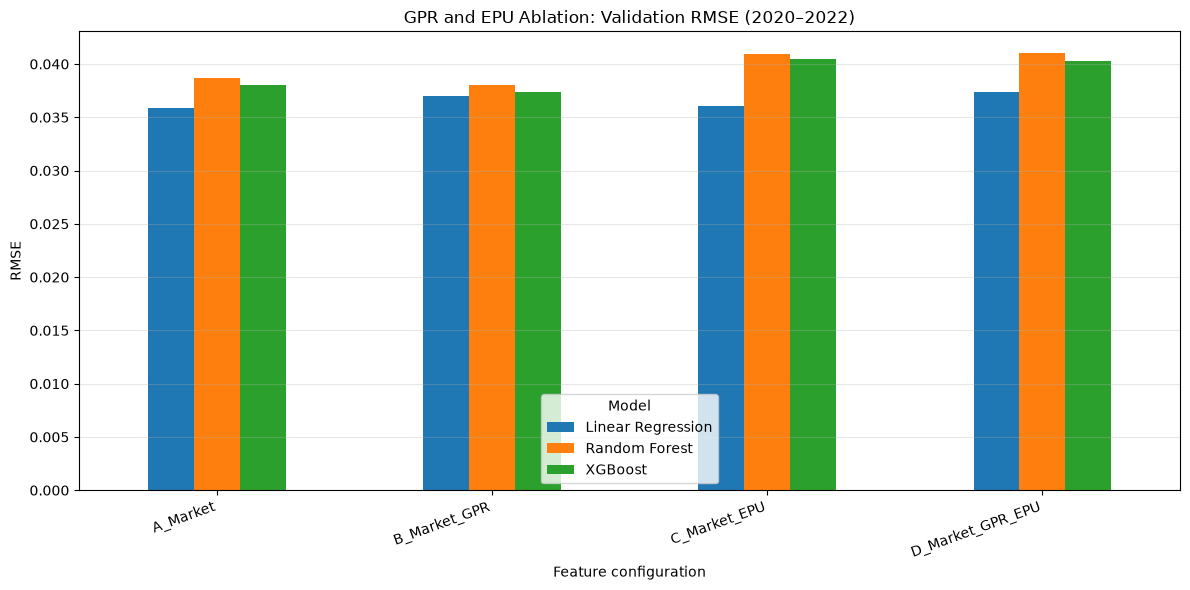

In [9]:
pivot_rmse = ablation_results_df.pivot(
    index="Feature_Set",
    columns="Model",
    values="RMSE"
)

ax = pivot_rmse.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "GPR and EPU Ablation: Validation RMSE (2020–2022)"
)

ax.set_xlabel("Feature configuration")
ax.set_ylabel("RMSE")

plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gpr_epu_ablation_rmse.png",
    dpi=300
)

plt.show()

In [10]:
ablation_results_df.to_csv(
    TABLES_DIR / "gpr_epu_ablation_metrics.csv",
    index=False
)

ablation_predictions_df.to_csv(
    TABLES_DIR / "gpr_epu_ablation_predictions.csv",
    index=False
)

improvement_df.to_csv(
    TABLES_DIR / "gpr_epu_ablation_improvements.csv",
    index=False
)

print("Notebook 16 results saved successfully!")

Notebook 16 results saved successfully!
